# Лабораторная работа 1: «Метод обратного распространения ошибки»

**Выполнил**: студент группы 3825М1ФИ2 Загребин Сергей

## Цели работы

**Цель** — изучить метод обратного распространения ошибки для обучения глубоких нейронных сетей на примере двухслойной полносвязной нейронной сети (один скрытый слой).

## Задачи работы

Выполнение лабораторной работы предполагает решение следующих задач:

1. Изучить общую схему работы метода обратного распространения ошибки с использованием стохастического градиентного спуска.
2. Вывести математические формулы для вычисления градиентов функции ошибки по параметрам нейронной сети и формул коррекции весов.
3. Загрузить набор данных [MNIST](https://www.kaggle.com/datasets/hojjatk/mnist-dataset), выполнить предобработку изображений и меток, если это необходимо.
4. Реализовать и протестировать метод обратного распространения ошибки для задачи классификации рукописных цифр из набора данных MNIST.

---

## Конфигурация нейронной сети

1. **Входной слой** содержит `w x h` нейронов, что соответствует разрешению одноканального изображения. Для набора MNIST это составляет `28 x 28`.
2. **Выходной слой** содержит `k` нейронов, что соответствует количеству классов изображений. Для задачи классификации рукописных цифр MNIST — 10 классов.
3. **Скрытый слой** содержит `s` нейронов (параметр).
4. **Параметры метода обучения**:
    - Скорость обучения (learning rate)
    - Размер пачки данных (batch size)
    - Количество эпох
5. **Функции активации**:
    - На скрытом слое — функция ReLU.
    - На выходном слое — функция softmax.
    - Входной слой не содержит функции активации.
6. **Функция ошибки** — кросс-энтропия. ***softmax вместе с кросс-энтропией упрощает вывод формул***.
7. **Контрольные параметры для демонстрации работы нейронной сети**:
    - Размер пачки данных: от 8 до 64 изображений (в зависимости от доступного объема памяти).
    - Скорость обучения: 0.1.
    - Количество скрытых нейронов `s`: 300.
    - Количество эпох: 20.

## Теоретическая часть

Рассмотрим нахождение градиента для весов одного слоя.

Введём обозначения:
$A \in \mathbb{R}^{m \times n}$, $x \in \mathbb{R}^n$, $b \in \mathbb{R}^m$, $z \in \mathbb{R}^m$, $f: \mathbb{R}^m \to \mathbb{R}$

$$z = Ax + b \quad y = f(z)$$

$$\frac{\partial y}{\partial A_{ij}} = \frac{\partial y}{\partial z_i} x_j \quad \frac{\partial y}{\partial b_{j}} = \frac{\partial y}{\partial z_j} $$

Обозначим ошибку на входе в функцию активации
$$\mathbf{g} = \nabla_z y = \frac{\partial y}{\partial z} = \left( \frac{\partial y}{\partial z_1}, \dots, \frac{\partial y}{\partial z_m} \right)^T$$
Тогда
$$\nabla_A y = \mathbf{g} x^T \quad \nabla_b y = \mathbf{g}$$

---

Между слоями, связанными ReLU:

$$ z_{i+1} = A_{i+1}y_i + b_{i+1} \quad y_i = \text{ReLU}(z_i) = \max(0, z_i)$$

$$ \mathbf{g_i} = \frac{\partial \mathcal{L}}{\partial z_i} = \frac{\partial \mathcal{L}}{\partial y_i} \frac{\partial y_i}{\partial z_i} = A_{i+1}^T g_{i+1} \odot \mathbb{I}(z_{i} > 0) $$

---

Рассмотрим нахождение градиента функции активации Softmax и ошибки кросс-энтропии для $K$ классов.

$$\hat y_i = \text{Softmax}(z)_i = \frac{e^{z_i}}{\sum_{k=1}^K e^{z_k}}, \quad i = 1, \dots, K$$

$$\mathcal{L} = -\sum_{k=1}^K y_k \ln \hat y_k = -\ln \hat y_c \quad \frac{\partial \mathcal{L}}{\partial \hat y_i} = -\frac{y_i}{\hat y_i}$$

Градиент для Softmax выражается как

$$\frac{\partial \hat y_i}{\partial z_j} = \hat y_i \delta_{ij} - \hat y_i \hat y_j, \quad \text{где } \delta_{ij} = \begin{cases} 1, & i = j \\ 0, & i \neq j \end{cases}$$

Найдём градиент ошибки на входе в функцию активации:
$$\mathbf{g}_i = \frac{\partial \mathcal{L}}{\partial z_i} = \sum_{k=1}^K \frac{\partial \mathcal{L}}{\partial \hat y_k} \frac{\partial \hat y_k}{\partial z_i} = \sum_{k=1}^K \left(-\frac{y_k}{\hat y_k}\right) (\hat y_k \delta_{ki} - \hat y_k \hat y_i) = $$

$$ = -\frac{y_i}{\hat y_i} \hat y_i + \sum_{k=1}^K \frac{y_k}{\hat y_k} \hat y_k \hat y_i = -y_i + \hat y_i \sum_{k=1}^K y_k = \hat y_i - y_i$$

In [7]:
import numpy as np
import time

class SimpleNetwork:
    def __init__(self, input_dim, hidden_dim, num_classes, learning_rate = 0.01):
        self.input_dim = input_dim
        self.hidden_dim = hidden_dim
        self.num_classes = num_classes
        self.lr = learning_rate

        # He (Kaiming) for ReLU
        self.W1 = np.random.randn(input_dim, hidden_dim) * np.sqrt(2.0 / input_dim)
        self.b1 = np.zeros((1, hidden_dim))

        # Xavier (Glorot) for Softmax
        self.W2 = np.random.randn(hidden_dim, num_classes) * np.sqrt(1.0 / hidden_dim)
        self.b2 = np.zeros((1, num_classes))

    @staticmethod
    def _relu(Z):
        return np.maximum(0, Z)

    @staticmethod
    def _softmax(Z):
        exp_Z = np.exp(Z)
        return exp_Z / np.sum(exp_Z, axis=1, keepdims=True)

    def forward(self, X):
        self.X = X

        self.Z1 = X @ self.W1 + self.b1
        self.Y1 = self._relu(self.Z1)

        self.Z2 = self.Y1 @ self.W2 + self.b2
        self.P = self._softmax(self.Z2)

        return self.P

    def compute_loss(self, Y_onehot):
        N = Y_onehot.shape[0]
        loss = -np.sum(Y_onehot * np.log(self.P + 1e-15)) / N
        return loss

    def backward(self, Y_onehot):
        N = Y_onehot.shape[0]

        G2 = (self.P - Y_onehot) / N

        dW2 = self.Y1.T @ G2
        db2 = np.sum(G2, axis=0, keepdims=True)

        G1 = (G2 @ self.W2.T) * (self.Z1 > 0)

        dW1 = self.X.T @ G1
        db1 = np.sum(G1, axis=0, keepdims=True)

        self.W2 -= self.lr * dW2
        self.b2 -= self.lr * db2
        self.W1 -= self.lr * dW1
        self.b1 -= self.lr * db1

    def fit(self, X, Y_labels, epochs = 10, batch_size = 64):
        N = X.shape[0]

        Y_onehot = np.zeros((N, self.num_classes))
        Y_onehot[np.arange(N), Y_labels] = 1.0

        for epoch in range(epochs):
            start_time = time.time()

            indices = np.random.permutation(N)
            X_shuffled = X[indices]
            Y_shuffled = Y_onehot[indices]

            for i in range(0, N, batch_size):
                X_batch = X_shuffled[i:i + batch_size]
                Y_batch = Y_shuffled[i:i + batch_size]

                self.forward(X_batch)
                self.backward(Y_batch)

            epoch_time = time.time() - start_time

            preds = self.forward(X)
            loss = self.compute_loss(Y_onehot)
            train_error = 1.0 - np.mean(np.argmax(preds, axis=1) == Y_labels)

            print(f"Epoch {epoch+1:02d}/{epochs:02d} | Loss: {loss:.4f} | Error: {train_error * 100:.2f}% | Time: {epoch_time:.2f}s")

    def predict(self, X):
        probs = self.forward(X)
        return np.argmax(probs, axis=1)

In [8]:
!pip install idx2numpy

In [9]:
from idx2numpy import convert_from_file
import kagglehub

def get_mnist():
    path = kagglehub.dataset_download("hojjatk/mnist-dataset")
    print("Path to MNIST dataset:", path)
    X_train = convert_from_file('/kaggle/input/mnist-dataset/train-images.idx3-ubyte')
    Y_train = convert_from_file('/kaggle/input/mnist-dataset/train-labels.idx1-ubyte')
    X_test  = convert_from_file('/kaggle/input/mnist-dataset/t10k-images.idx3-ubyte')
    Y_test  = convert_from_file('/kaggle/input/mnist-dataset/t10k-labels.idx1-ubyte')
    return (X_train, Y_train, X_test, Y_test)

X_train, Y_train, X_test, Y_test = get_mnist()

print("X_train.shape:", X_train.shape)
print("Y_train.shape:", Y_train.shape)
print("X_test.shape:", X_test.shape)
print("Y_test.shape:", Y_test.shape)

Using Colab cache for faster access to the 'mnist-dataset' dataset.
Path to MNIST dataset: /kaggle/input/mnist-dataset
X_train.shape: (60000, 28, 28)
Y_train.shape: (60000,)
X_test.shape: (10000, 28, 28)
Y_test.shape: (10000,)


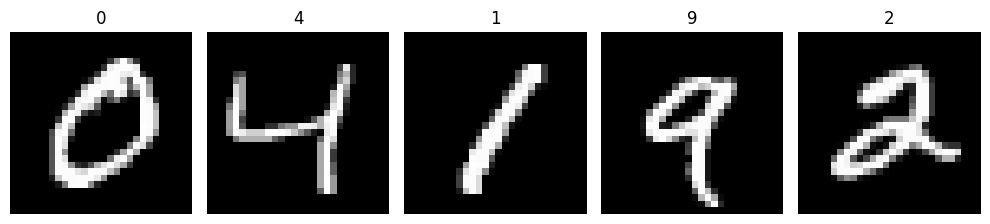

In [10]:
from matplotlib import pyplot as plt

show_ids = list(range(1, 6))

def show_images(images, labels):
    num_images = len(images)
    fig, axes = plt.subplots(1, num_images, figsize=(num_images * 2, 3.5))

    if num_images == 1:
        axes = [axes]

    for i in range(num_images):
        axes[i].imshow(images[i], cmap='gray')
        axes[i].set_title(f"{labels[i]}")
        axes[i].axis('off')

    plt.tight_layout()
    plt.show()

show_images(X_train[show_ids], Y_train[show_ids])

In [11]:
np.random.seed(42)

def run_pipeline(X_train, Y_train, X_test, Y_test):
    X_train_flat = X_train.reshape(X_train.shape[0], -1).astype(float) / 255.0
    X_test_flat = X_test.reshape(X_test.shape[0], -1).astype(float) / 255.0

    mlp = SimpleNetwork(input_dim=784, hidden_dim=300, num_classes=10, learning_rate=0.1)

    print("--- Training ---")
    mlp.fit(X_train_flat, Y_train, epochs=20, batch_size=64)

    print("--- Testing ---")
    test_preds = mlp.predict(X_test_flat)
    test_error = 1.0 - np.mean(test_preds == Y_test)
    print(f"Error on test dataset: {test_error * 100:.2f}%")
    return mlp

model = run_pipeline(X_train, Y_train, X_test, Y_test)

--- Training ---
Epoch 01/20 | Loss: 0.2419 | Error: 6.83% | Time: 3.95s
Epoch 02/20 | Loss: 0.1607 | Error: 4.57% | Time: 6.97s
Epoch 03/20 | Loss: 0.1232 | Error: 3.43% | Time: 4.65s
Epoch 04/20 | Loss: 0.0987 | Error: 2.72% | Time: 6.92s
Epoch 05/20 | Loss: 0.0903 | Error: 2.58% | Time: 3.87s
Epoch 06/20 | Loss: 0.0713 | Error: 1.93% | Time: 6.08s
Epoch 07/20 | Loss: 0.0635 | Error: 1.70% | Time: 3.88s
Epoch 08/20 | Loss: 0.0562 | Error: 1.45% | Time: 3.84s
Epoch 09/20 | Loss: 0.0487 | Error: 1.23% | Time: 6.56s
Epoch 10/20 | Loss: 0.0447 | Error: 1.15% | Time: 3.81s
Epoch 11/20 | Loss: 0.0380 | Error: 0.92% | Time: 6.90s
Epoch 12/20 | Loss: 0.0365 | Error: 0.89% | Time: 4.63s
Epoch 13/20 | Loss: 0.0309 | Error: 0.66% | Time: 6.91s
Epoch 14/20 | Loss: 0.0287 | Error: 0.60% | Time: 3.84s
Epoch 15/20 | Loss: 0.0280 | Error: 0.62% | Time: 6.86s
Epoch 16/20 | Loss: 0.0235 | Error: 0.43% | Time: 3.77s
Epoch 17/20 | Loss: 0.0214 | Error: 0.37% | Time: 4.53s
Epoch 18/20 | Loss: 0.0199 | Er

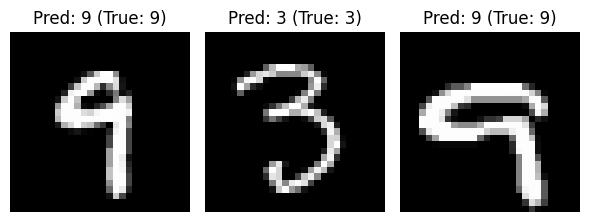

In [12]:
test_idx = np.random.choice(len(X_test), size=3, replace=False)

sample_images = X_test[test_idx]
sample_labels_true = Y_test[test_idx]

sample_images_flat = sample_images.reshape(3, -1).astype(float) / 255.0
sample_predictions = model.predict(sample_images_flat)

labels = [f"Pred: {pred} (True: {true})"
    for pred, true in zip(sample_predictions, sample_labels_true)]

show_images(sample_images, labels)